### Wine Quality Prediction
##### Objective: Train and compare multiple classification models to predict the quality score of wine (typically a scale of 3–8) based on its physicochemical properties such as acidity, density, and alcohol content.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# Load wine data
wine_quality = pd.read_csv('winequality-red.csv')

# Inspect structure
print(f'{wine_quality.shape}\n')
print(f'{wine_quality.info()}\n')
print(f'{wine_quality.head()}\n')
print(f'{wine_quality.describe()}\n')

# Check for missing values
print(wine_quality.isna().sum())

(1599, 12)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB
None

   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              

quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64


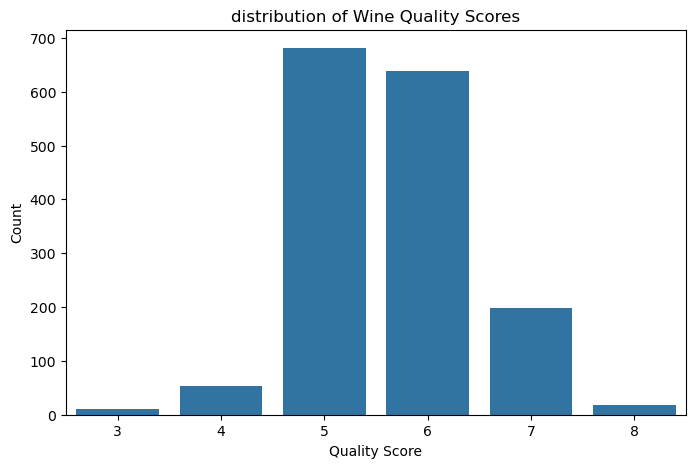

In [3]:
# Class distribution of quality scores
print(wine_quality['quality'].value_counts().sort_index())

# Visualize distribution of quality scores
plt.figure(figsize=(8, 5))
sns.countplot(x='quality', data=wine_quality)
plt.title('distribution of Wine Quality Scores')
plt.xlabel('Quality Score')
plt.ylabel('Count')
plt.show()

The distribution of wine quality scores is clearly imbalanced ad roughly bell-shaped, centered on the 'average' scores of 5 and 6. These two categories alone account for over 82% of the dataset (681 and 638 samples respectively), while wines rated 7have far fewer samples (199), and the extreme categories are 3, 4, and 8 which are rare together making up less than 5% of the data. No wines were rated 1, 2, 9, 10, meaning the dataset only covers a middle band of the theoretical 0-10 scale. This skew reflect a real-world pattern: most wines are of average quality, expectional and poor wines are uncommon. For modelling, this means the minority classes (3, 4, 8) risk being underpresented or ignored entirely, especially by classifiers that optimize for overall accurancy.

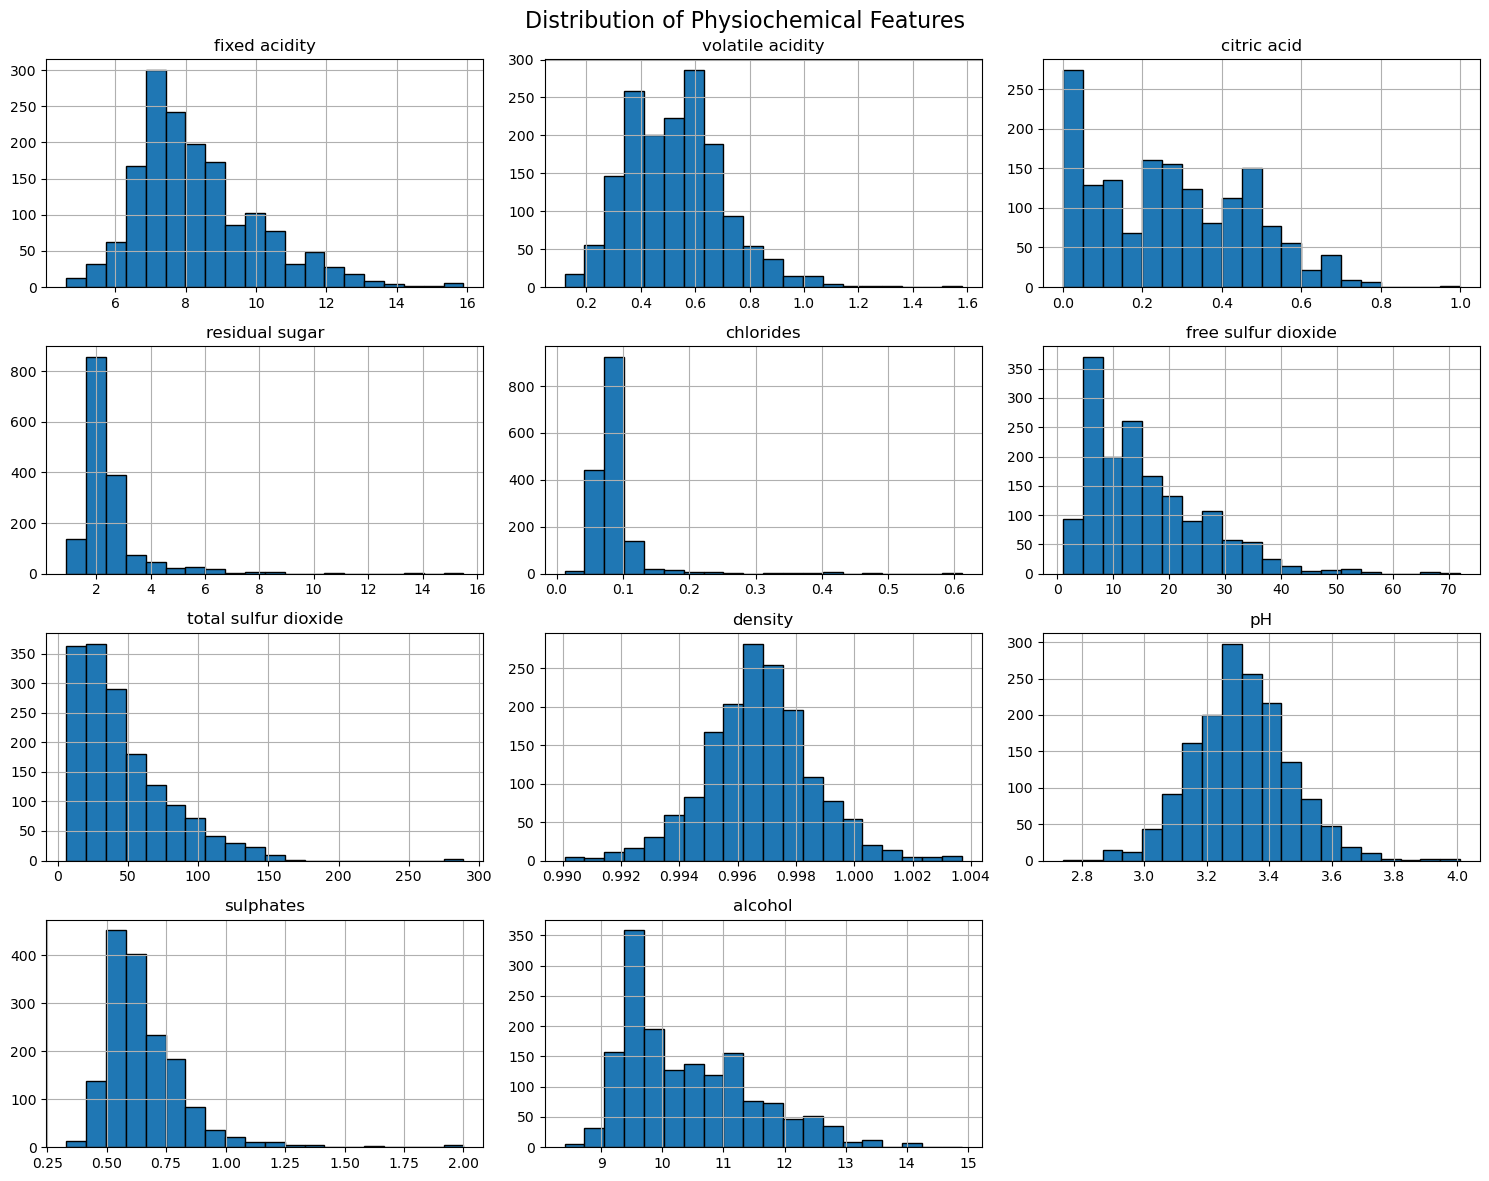

In [4]:
# distribution plots for all chemical features
features = wine_quality.columns.drop('quality')

wine_quality[features].hist(bins=20, figsize=(15, 12), edgecolor='black')
plt.suptitle('Distribution of Physiochemical Features', fontsize=16)
plt.tight_layout()
plt.show()

The features show a mix of distribution shapes:

- **Fixed acidity, volatile acidity, Sulphates, and total sulfur dioxide** are right-skewed, with most values clustered at the lower end and a long tail of higher values - some clear outliers stretching toward the extremes.
- **Residual sugar and chlorides** are heavily right-skewed and sharply peaked, with the vast majority of wines clustered in a very narrow range and a small number of extreme outliers stretching the axis out to 16 and beyond.
- **Citric acid** is unusual - a large spike at 0 (many wines contain none), then a fairly flat, irregular spread across the rest of its .
range.
- **Free sulfur dioxide** is also right-skewed, peaking early and tailing off gradually.
- **Density and pH** are the most normally distribution features, forming clear symmetric bell shapes.
- **Alcohol** is the right-skewed with a strong peak around 9-10%, tapering off toward higher concentrations (up to ~14-15%).

Overall, most features deviate from normality and contain outliers. This is useful context: tree-based models like Random Forest are robust to this skew, but SVC and SGD (which rely on distance/radient calculations) will benefit from feature scaling, and outliers amy need to be considered when interpreting results.

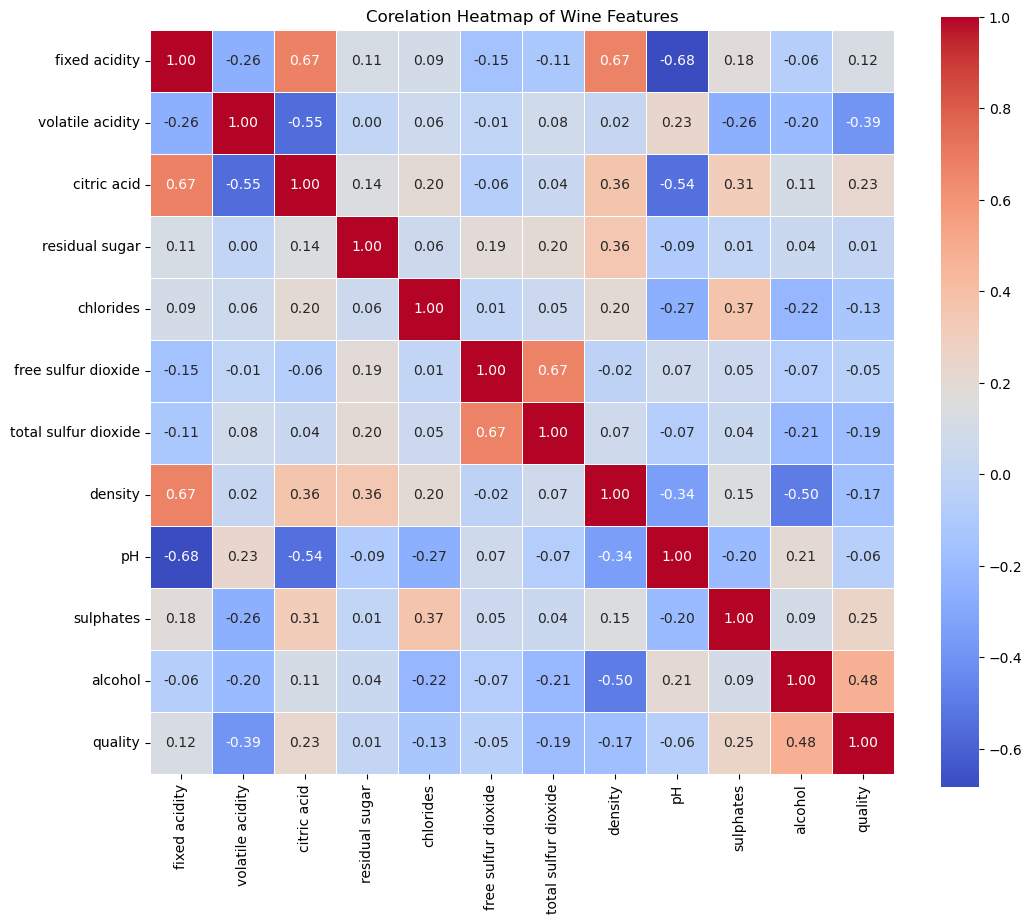

In [5]:
# Correlation Heatmap
plt.figure(figsize=(12, 10))
corr = wine_quality.corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', square=True, linewidth=0.5)
plt.title('Corelation Heatmap of Wine Features')
plt.show()

Looking at correlations with the target variable, `quality`:

- **Alcohol** has the strongest positive correlation with quality (0.48) - higher alcohol content tends to associate with higher-rated wines.
-  **Volatile acidity** has the strongest negative correlation with quality (-0.39) - wines with more volatile acidity (vinegar-like taste) tend to be rated lower.
-  **Sulphates** (0.25) and **citric acid** (0.23) show mild positive correlations with quality.
-  **Density** (-0.17) and **chlorides** (-0.13) show mild negative correlations.
-  Most other features (residual sugar, free/total sulphur dioxide, pH, fixed acidity) show very weak concentration with quality on their own.

Some notable correlations **between features** are worth flagging for modelling:
- **Fixed acidity and density** (0.67) and **fixed acidity and citric acid** (0.67) are strongly correlated - some redundancy here.
- **Fixed acidity and pH** (-0.68) - a strong negative correlation, as expected (more acid = lower pH).
- **Free sulphur dioxide and total sulphur dioxide** (0.67) are strongly correlated, which makes sense since one is a subset of the other.
- **Alcohol and density** (-0.50) are moderately negative correlated.

These multicollinear pairs won't hurt Random Forest much, but could affect the stability of coefficients in linear-leaning models - worth keeping in mind when interpreting SVC/SGD results later.

##### Feature Engineering: Binning Quality Scores

Given the class imbalance observed above (extremes like 3, 4, and 8 have very few samples), we bin the quality scores into broader categories rather than treating this as 6-class classification. I chose a **3-class scheme** - low, medium, high - because a binary split (e.g., good/bad) would be simpler but throws away useful naunce in the "average" wines that make up most of the dataset, while a 3-class spli gives the model wider category boundaries so minority classes aren't drowned out.

**Binning scheme:**
- Low: quality 3-4
- Medium: quality 5-6
- High: quality 7-8

quality_label
medium    1319
high       217
low         63
Name: count, dtype: int64


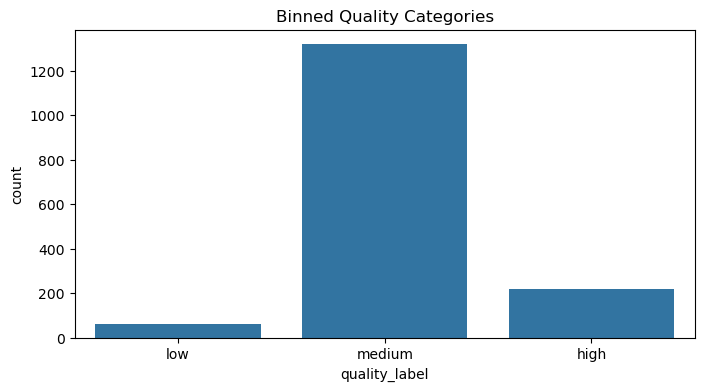

In [6]:
def bin_quality(q):
    if q <= 4:
        return 'low'
    elif q <= 6:
        return 'medium'
    else:
        return 'high'

wine_quality['quality_label'] = wine_quality['quality'].apply(bin_quality)

print(wine_quality['quality_label'].value_counts())

plt.figure(figsize=(8,4))
sns.countplot(x='quality_label', data=wine_quality, order=['low', 'medium', 'high'])
plt.title('Binned Quality Categories')
plt.show()

In [7]:
from sklearn.model_selection import train_test_split

X = wine_quality[features]  # physiochemical features
Y = wine_quality['quality_label']

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y,
    test_size=0.2,
    random_state=42,
    stratify=Y
)

print('Train shape:', X_train.shape)
print('Test shape:', X_test.shape)
print('\nTrain class distribution:\n', Y_train.value_counts(normalize=True))
print('\nTest class distribution:\n', Y_test.value_counts(normalize=True))

Train shape: (1279, 11)
Test shape: (320, 11)

Train class distribution:
 quality_label
medium    0.824863
high      0.136044
low       0.039093
Name: proportion, dtype: float64

Test class distribution:
 quality_label
medium    0.825000
high      0.134375
low       0.040625
Name: proportion, dtype: float64


I trained three classifiers on the stratified split. Since SGD and SVC are distance/gradient-based, I scaled the features first - Random Forest desn't need scaling but I'll apply it uniformly for a fair, simple pipeline.

In [8]:
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import SGDClassifier
from sklearn.svm import SVC

# Scale features (helps SGD & SVC; harmless for Random forest)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Random Forest
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, Y_train)  # tree-based, doesn't need scaling

# SGD Classifier
sgd = SGDClassifier(random_state=42)
sgd.fit(X_train_scaled, Y_train)

# Support Vector Classifier
svc = SVC(random_state=42)
svc.fit(X_train_scaled, Y_train)

print('All three models trained.')

All three models trained.


I evaluate each model using accuracy, a full classification report (precision, recall, F1 per class), and a confusion matrix to see exactly where each model confuses classes - especially the minority "low" class.


Random Forest

Accuracy: 0.8656

Classification Report:
              precision    recall  f1-score   support

        high       0.71      0.51      0.59        43
         low       0.00      0.00      0.00        13
      medium       0.88      0.97      0.92       264

    accuracy                           0.87       320
   macro avg       0.53      0.49      0.51       320
weighted avg       0.82      0.87      0.84       320



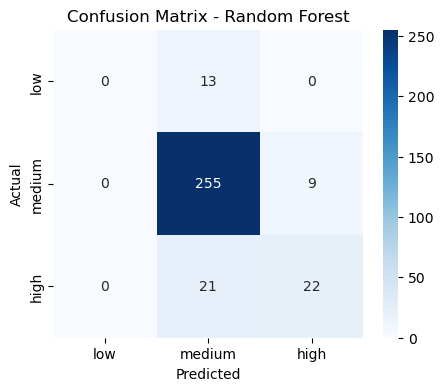


SGD Classifier

Accuracy: 0.8250

Classification Report:
              precision    recall  f1-score   support

        high       0.52      0.33      0.40        43
         low       0.00      0.00      0.00        13
      medium       0.86      0.95      0.90       264

    accuracy                           0.82       320
   macro avg       0.46      0.42      0.43       320
weighted avg       0.78      0.82      0.80       320



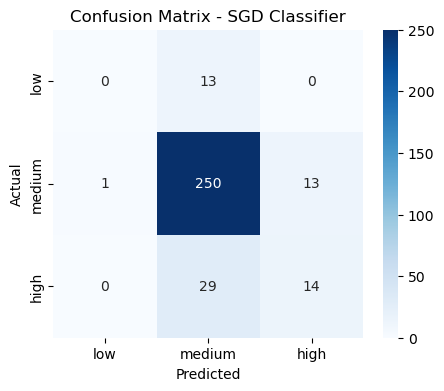


Support Vector Classifier

Accuracy: 0.8438

Classification Report:
              precision    recall  f1-score   support

        high       0.64      0.33      0.43        43
         low       0.00      0.00      0.00        13
      medium       0.86      0.97      0.91       264

    accuracy                           0.84       320
   macro avg       0.50      0.43      0.45       320
weighted avg       0.79      0.84      0.81       320



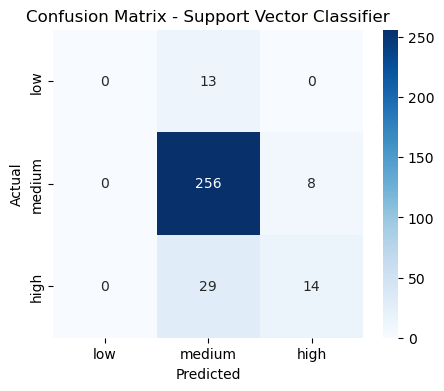

In [9]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

def evaluate_model(name, Y_true, Y_pred):
    print(f'\n{'='*50}')
    print(f'{name}')
    print(f'\n{'='*50}')
    print(f'Accuracy: {accuracy_score(Y_true, Y_pred):.4f}\n')
    print('Classification Report:')
    print(classification_report(Y_true, Y_pred, zero_division=0))

    cm = confusion_matrix(Y_true, Y_pred, labels=['low', 'medium', 'high'])
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['low', 'medium', 'high'],
                yticklabels=['low', 'medium', 'high'])
    plt.title(f'Confusion Matrix - {name}')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()

# Random Forest (unscaled)
Y_pred_rf = rf.predict(X_test)
evaluate_model('Random Forest', Y_test, Y_pred_rf)

# SGD (scaled)
Y_pred_sgd = sgd.predict(X_test_scaled)
evaluate_model('SGD Classifier', Y_test, Y_pred_sgd)

# SGD (scaled)
Y_pred_svc = svc.predict(X_test_scaled)
evaluate_model('Support Vector Classifier', Y_test, Y_pred_svc)

All three models achieve reasonably high overall accuracy (82-87%), but this is misleading - it's driven almost entirely by the dominant "medium" class (264 of 320 test samples). Looking at per-class performance tells a very different story:

- **"Low class"**: All three models completely fail to identify any low-quality wines (0.00 recall and precision across the board). With only 13 training examples, none of the models learned meaniful patterns for this class - every single "low" sample was misclassified as "medium".
- **"High class"**: Random Forest performs noticeably better here (0.51 recall) than SGD (0.33) or SVC (0.33), correctly identifying about half of high-quality wines versus roughly a third for the others.
- **"Medium class"**: All three models handle this well (95-97% recall), unsurprising given it dominates the training data.

**Random Forest is the clear best performer** among the three - highest overall accuracy (86.6%) and meanifully better recall on the minority "high" class, likely because tree-based ensembles handle class imbalance and non-linear feature interactions better than linear/margin-based models here. However, none of the three models are usable for detecting genuinely "low" quality wines without futher intervention (e.g., SMOTE oversamlpling, class-weighting, or collecting more low-quality samples).

**Feature Importance (Random Forest)**

I'll extract and visualize which physiochemical properties the Random Forest model relies on most heavily when predicting wine quality.

                 feature  importance
10               alcohol    0.146866
1       volatile acidity    0.130046
9              sulphates    0.104467
7                density    0.092413
2            citric acid    0.085064
0          fixed acidity    0.083301
6   total sulfur dioxide    0.080194
3         residual sugar    0.073206
4              chlorides    0.071864
8                     pH    0.067959
5    free sulfur dioxide    0.064619


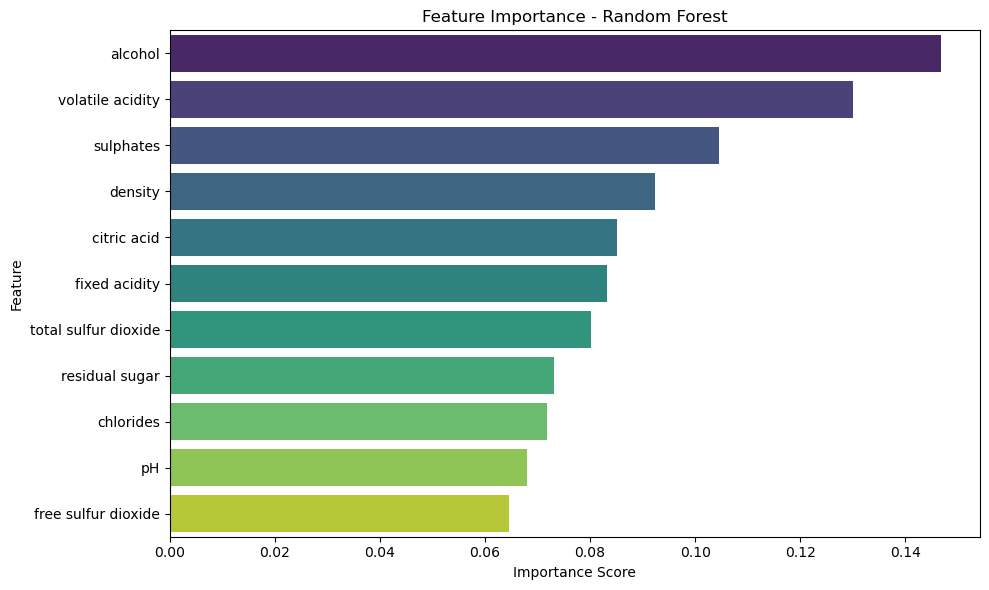

In [10]:
# Get features importance
importances = rf.feature_importances_
feat_importance_df = pd.DataFrame({
    'feature': features,
    'importance': importances
}).sort_values('importance', ascending=False)

print(feat_importance_df)

plt.figure(figsize=(10, 6))
sns.barplot(x='importance', y='feature', data=feat_importance_df, hue='feature', palette='viridis', legend=False)
plt.title('Feature Importance - Random Forest')
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

The Random Forest's feature importance ranking closely mirrors what was seen in the correlation heatmap:

- **Alcohol (0.147)** is the single most important predictor - consistent with its strongest correlation to quality (0.48) observed earlier.
- **Volatile acidity (0.130)** ranks second, matching its strongest negative correlation with quality (-0.39).
- **Sulphates (0.104)** and **citric acid (0.085)** also rank fairly high, both of which showes mild positive correlations with quality in the heatmap.
- Interestingly, **density (0.092)** ranks higher in importance than its raw correlation with quality (-0.17) would suggest - this is likely because Random Forest captures its interaction effects with other features (like acohol, with which it's strongly negatively correlated at -0.50) rather than relying on a simple linear relationship.
-  The least important features - **ph** and **free sulfur dioxide**  - also showed the weakest correlations with quality, reinforcing the consistency between the two analyses.

This agreement between correlation and feature importance gives confidence that alcohol and volatile acidity are genuinely the strongest drivers of wine quality in this dataset, rather than an artifact of the model.

**Model Comparison Summary**

The table below summaries the key metrics for all three classifiers, evaluated on the same stratified test set (320 samples: 264 medium, 43 high, 13 low).

In [16]:
comparison_data = {
    'Model': ['Random Forest', 'SGD Classifier', 'Support Vector Classifier'],
    'Accuracy': [0.8656, 0.8250, 0.8438],
    'Precision (macro avg)': [0.53, 0.46, 0.50],
    'Recall (macro avg)': [0.49, 0.42, 0.43],
    'F1-score (macro avg)': [0.51, 0.43, 0.45],
    'Recall - Low': [0.00, 0.00, 0.00], 
    'Recall - Medium': [0.97, 0.95, 0.97],
    'Recall - High': [0.51, 0.33, 0.33]
}

comparison_df = pd.DataFrame(comparison_data)
print(comparison_df.to_string(index=False))

                    Model  Accuracy  Precision (macro avg)  Recall (macro avg)  F1-score (macro avg)  Recall - Low  Recall - Medium  Recall - High
            Random Forest    0.8656                   0.53                0.49                  0.51           0.0             0.97           0.51
           SGD Classifier    0.8250                   0.46                0.42                  0.43           0.0             0.95           0.33
Support Vector Classifier    0.8438                   0.50                0.43                  0.45           0.0             0.97           0.33


**Summary:** Random Forest outperforms the other two models on every aggregate metrics - highest accuracy (86.6%), highest macro-averaged precision/recall/F1, and notably better recall on the "high" quality class (51% vs. 33% for both SGD and SVC). All three models fail identically on the "low" class due to severe underrepresentation in the training data (only 63 samples out of 1,599). Between SGD and SVC, SVC edges out slightly on accuracy and macro F1, but the difference is marginal - both are meanifully weaker than Random Forest.

#### Conclusion
**Random Forest is the most suitable model for deployment** among the three classifiers tested. It achieved the highest overall accuracy (86.6%) and the best macro-averaged performance across precision, recall, and F1-score, indicating it generalizes better across all three quality categories rather than just the majority class. Most notably, it correctly identified 51% of high-quality wines - meanifully better than SGD and SVC  - which is important since correctly flagging high-quality wines has real business value (e.g., premium pricing, quality control).

Beyond raw performance, Random Forest has practical advantages for deployment:
- **No feature scaling required**, simplifying the production pipeline.
- **Feature importance is directly interpretable**, useful for explaining predictions to stakeholders (e.g., winemakers wanting to know properties to adjust).
- **Robust to skewed, outlier-heavy distributions** observing features like residual sugar and chlorides, without needing extensive preprocessing.

**A key limitation to flag**, however, is that none of the three models - including Random Forest - could reliably detect "low" quality wines, due to severe class imbalance (only 63 of 1,599 samples). Before deploying this model in a real setting, it would be worth addressing this with techniques such as:
- Oversampling the minority class (e.g., SMOTE)
- Class-weighting during training (`class_weight='balanced'`)
- Collecting more low-quality wine samples if possible

Without addressing this, the model should be understood as reliable for distinguishing medium vs. high quality wines, but not for flagging poor-quality ones - a meaniful caveat for any real-world deployment.